# 01 - Next Candle Prediction

Predict the next 1-hour ETHUSDT candle return.


## Setup

In [4]:
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (12, 4)
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
FEATURES = ["ret_1","ret_5","ret_20","vol_20","rsi_14","macd_hist","atr_14","sma_50","sma_200"]

def build(timeframe="1d", horizon=1):
    df = load_ohlcv(timeframe=timeframe)
    df = add_all(df).copy()
    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()
    df["target"] = df["close"].pct_change(horizon).shift(-horizon)
    return df.dropna()

def metrics(y, p):
    return {"rmse": float(np.sqrt(((y-p)**2).mean())),
            "mae":  float(np.abs(y-p).mean()),
            "dir_accuracy": float(((p>0)==(y>0)).mean())}

ModuleNotFoundError: No module named 'analysis'

## 1. Load 1h candles

In [ ]:
df = build(timeframe="1h", horizon=1)
print("rows:", len(df))
print("range:", df.index.min(), "->", df.index.max())
df[["close","ret_1","vol_20","target"]].tail()

rows: 1551
range: 2026-07-31 02:00:00 -> 2026-10-03 16:00:00


,close,ret_1,vol_20,target
date,,,,
2026-10-03 12:00:00,2682.67,-0.000700,0.002185,-0.000253
2026-10-03 13:00:00,2681.99,-0.000253,0.002138,0.000585
2026-10-03 14:00:00,2683.56,0.000585,0.001297,-0.000697
2026-10-03 15:00:00,2681.69,-0.000697,0.001303,-0.000004
2026-10-03 16:00:00,2681.68,-0.000004,0.001151,0.002733


## 2. Fit Ridge

{
  "rmse": 0.003976924753408246,
  "mae": 0.0028296381244864374,
  "dir_accuracy": 0.484
}


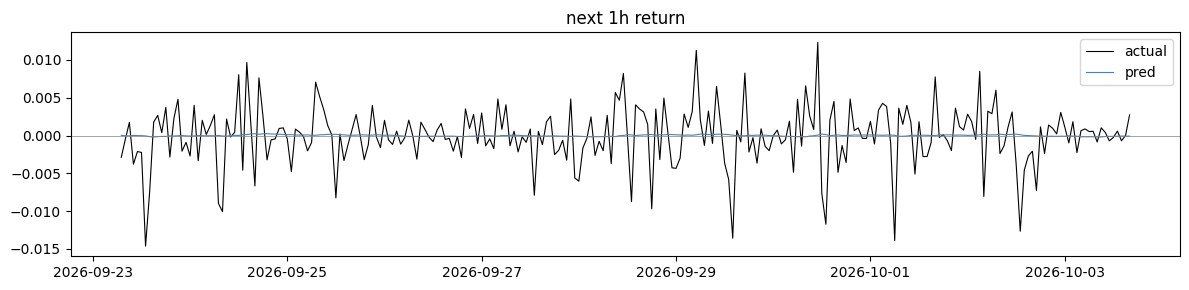

In [ ]:
train = df.iloc[:-250]; test = df.iloc[-250:]
model = Ridge(alpha=1.0).fit(train[FEATURES].values, train["target"].values)
pred = model.predict(test[FEATURES].values); y = test["target"].values
m = metrics(y, pred)
print(json.dumps(m, indent=2))

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(test.index, y, label="actual", color="black", lw=0.8)
ax.plot(test.index, pred, label="pred", color="steelblue", lw=0.8)
ax.axhline(0, color="gray", lw=0.5)
ax.set_title("next 1h return")
ax.legend()
plt.tight_layout(); plt.show()

## 3. Forecast next hour

In [ ]:
r = float(model.predict(df[FEATURES].iloc[[-1]].values)[0])
last = float(df["close"].iloc[-1])
print("as of       :", df.index[-1])
print("last close  :", round(last, 2))
print("pred return :", f"{r*100:+.4f}%")
print("pred close  :", round(last*(1+r), 2))
print("direction   :", "UP" if r > 0 else "DOWN")

(OUT / "next_candle.json").write_text(json.dumps(
    {"as_of": str(df.index[-1]), "last_close": last,
     "next_ret": r, "next_close": last*(1+r), "metrics": m}, indent=2))
print("wrote next_candle.json")

as of       : 2026-10-03 16:00:00
last close  : 2681.68
pred return : -0.0075%
pred close  : 2681.48
direction   : DOWN
wrote next_candle.json


## Notes

1h is more tractable than daily. Watch magnitude, not just sign.
